# CTU-13 Scenario 42 — Botnet C2 Behavioral Feature Engineering (Strict Online Causal Correction)
## SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

### Objective & Real-Time Operational Constraint
This notebook executes a strict **temporal causality and online-safety correction** to the Botnet C2 behavioral feature engineering pipeline.

In real-time network defense, network flows arrive as a streaming sequence. For a flow arriving at timestamp $T$:
1. Every **ONLINE_SAFE** feature must strictly depend **only** on:
   - Characteristics of the current flow at time $T$.
   - Historical traffic observed **before or at time $T$** ($t \le T$).
   - Preceding observations within sliding temporal windows ($[T - W, T]$).
2. **ZERO Future-Information Leakage**: No feature may use full-dataset aggregates, global group averages, or future flow timestamps ($t > T$).
3. **ZERO Target Leakage**: No feature may reference ground-truth labels (`Label`, `TrafficClass`, `BinaryLabel`).
4. **Training-Period Threshold Calibration**: Baseline statistical thresholds (e.g. high-frequency quantiles, median duration thresholds, and imputation values) are calibrated **strictly on a designated historical Training Period (first 70% of chronological flows)** and applied forward without leaking future test distribution statistics.

> **Scope Restriction**: This notebook performs causal feature engineering and dataset generation only. No machine learning models (DBSCAN / Random Forest / Isolation Forest) are trained in this step.

### 1. Import Libraries
Import required data science, numerical, and visualization libraries.

In [1]:
import os
import sys
import gc
import warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display configurations
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Pandas version: 3.0.6
NumPy version: 2.5.3


### 2. Load Dataset & Strict Chronological Ordering
Load preprocessed CTU-13 binary data (`ctu13_botnet_binary.csv`) and sort strictly chronologically by `StartTime`.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

input_csv_path = project_root / 'data' / 'processed' / 'CTU13' / 'ctu13_botnet_binary.csv'
processed_dir = project_root / 'data' / 'processed' / 'CTU13'
processed_dir.mkdir(parents=True, exist_ok=True)

if not input_csv_path.exists():
    raise FileNotFoundError(f"Input dataset not found at {input_csv_path}")

df = pd.read_csv(input_csv_path)
df['StartTime'] = pd.to_datetime(df['StartTime'], errors='coerce', utc=True)

# Strict chronological sorting to simulate real-time traffic arrival
df = df.sort_values(by='StartTime').reset_index(drop=True)
n_rows = len(df)

print(f"Loaded Dataset: {input_csv_path.name}")
print(f"Total Rows: {n_rows:,} | Columns: {len(df.columns)}")
print(f"Chronological Span: {df['StartTime'].min()} to {df['StartTime'].max()}\n")

display(df.head(5))

Loaded Dataset: ctu13_botnet_binary.csv
Total Rows: 71,219 | Columns: 17
Chronological Span: 2011-08-10 09:46:53.160043+00:00 to 2011-08-10 15:54:07.198435+00:00



,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label,TrafficClass,BinaryLabel
0,2011-08-10 09:46:53.160043+00:00,0.0000,udp,147.32.80.9,53,->,147.32.86.111,54230,INT,0.0000,NaN,1,141,141,flow=From-Normal-V42-UDP-CVUT-DNS-Server,Normal,0
1,2011-08-10 09:46:54.045343+00:00,0.0000,udp,147.32.80.9,53,->,147.32.86.111,58314,INT,0.0000,NaN,1,247,247,flow=From-Normal-V42-UDP-CVUT-DNS-Server,Normal,0
2,2011-08-10 09:46:54.460552+00:00,0.0000,udp,147.32.80.9,53,->,147.32.86.111,54823,INT,0.0000,NaN,1,173,173,flow=From-Normal-V42-UDP-CVUT-DNS-Server,Normal,0
3,2011-08-10 09:46:54.779125+00:00,0.0003,udp,147.32.84.134,40693,<->,147.32.80.9,53,CON,0.0000,0.0000,2,207,72,flow=From-Normal-V42-Jist,Normal,0
4,2011-08-10 09:46:54.779641+00:00,0.0003,udp,147.32.84.134,47415,<->,147.32.80.9,53,CON,0.0000,0.0000,2,247,72,flow=From-Normal-V42-Jist,Normal,0


### 3. Current-Flow Metrics & Protocol Indicators
Compute flow rates, packet sizes, and protocol indicators that depend exclusively on the current flow packet attributes.

In [3]:
# Safe division for zero duration flows
safe_dur = np.where(df['Dur'] > 0, df['Dur'], np.nan)

df['PacketsPerSecond'] = np.where(df['Dur'] > 0, df['TotPkts'] / safe_dur, np.nan)
df['BytesPerSecond'] = np.where(df['Dur'] > 0, df['TotBytes'] / safe_dur, np.nan)
df['SourceBytesPerSecond'] = np.where(df['Dur'] > 0, df['SrcBytes'] / safe_dur, np.nan)
df['BytesPerPacket'] = np.where(df['TotPkts'] > 0, df['TotBytes'] / df['TotPkts'], np.nan)
df['PacketsPerByte'] = np.where(df['TotBytes'] > 0, df['TotPkts'] / df['TotBytes'], np.nan)
df['DestinationBytesApprox'] = np.maximum(0, df['TotBytes'] - df['SrcBytes'])

safe_tot_bytes = np.where(df['TotBytes'] > 0, df['TotBytes'], np.nan)
df['SourceByteRatio'] = np.where(df['TotBytes'] > 0, df['SrcBytes'] / safe_tot_bytes, 0.0)

# Current-flow protocol indicators
df['Proto_UDP'] = (df['Proto'].str.lower() == 'udp').astype(int)
df['Proto_TCP'] = (df['Proto'].str.lower() == 'tcp').astype(int)
df['Proto_ICMP'] = (df['Proto'].str.lower() == 'icmp').astype(int)

# Direction indicators
dir_clean = df['Dir'].str.strip()
df['Dir_Bidirectional'] = (dir_clean == '<->').astype(int)
df['Dir_Unidirectional'] = (dir_clean.isin(['->', '<-'])).astype(int)
df['Dir_Unknown'] = (dir_clean == '<?>').astype(int)

# Top 5 connection state indicators
state_clean = df['State'].str.strip()
top_states = state_clean.value_counts().head(5).index.tolist()
for st in top_states:
    col_name = f"State_{st.replace('-', '_').replace('?', 'UNK')}"
    df[col_name] = (state_clean == st).astype(int)

display(df[['PacketsPerSecond', 'BytesPerSecond', 'SourceBytesPerSecond', 'BytesPerPacket', 'SourceByteRatio']].describe().T)

,count,mean,std,min,25%,50%,75%,max
PacketsPerSecond,68475.0000,2070.2512,5331.7272,0.0008,6.2844,39.6385,4444.4444,500000.0000
BytesPerSecond,68475.0000,283463.6743,662780.4136,0.0500,907.1615,6322.2112,513441.2487,75250000.0000
SourceBytesPerSecond,68475.0000,79021.9685,196977.4992,0.0000,267.0252,2046.9632,167050.7096,18500000.0000
BytesPerPacket,71219.0000,139.3399,113.8294,60.0000,72.0000,111.0000,157.0000,1225.1779
SourceByteRatio,71219.0000,0.4601,0.2863,0.0000,0.2698,0.3532,0.5679,1.0000


### 4. Causal Inter-Arrival Time & Expanding Statistics
Calculate inter-arrival time (`IAT_SrcDst`) against the **immediate previous flow** in the same communication triplet (`SrcAddr`, `DstAddr`, `Dport`).
Calculate running statistics (running mean, std, min, max) using **expanding historical observations ($t \le T$) only**.

In [4]:
group_cols = ['SrcAddr', 'DstAddr', 'Dport']

# In chronological order, diff() yields time elapsed from the previous observed flow
df['IAT_SrcDst'] = df.groupby(group_cols)['StartTime'].diff().dt.total_seconds()
df['TimeSincePrev_SrcDst'] = df['IAT_SrcDst']

# Offline exploratory feature (LOOKAHEAD DEPENDENCY: marked OFFLINE_ONLY)
df['TimeUntilNext_SrcDst'] = (df.groupby(group_cols)['StartTime'].shift(-1) - df['StartTime']).dt.total_seconds()

# Causal running statistics (expanding window per communication triplet)
df['IAT_RunningMean_SrcDst'] = df.groupby(group_cols)['IAT_SrcDst'].transform(lambda s: s.expanding().mean())
df['IAT_RunningStd_SrcDst'] = df.groupby(group_cols)['IAT_SrcDst'].transform(lambda s: s.expanding().std())
df['IAT_RunningMin_SrcDst'] = df.groupby(group_cols)['IAT_SrcDst'].transform(lambda s: s.expanding().min())
df['IAT_RunningMax_SrcDst'] = df.groupby(group_cols)['IAT_SrcDst'].transform(lambda s: s.expanding().max())

# Causal Coefficient of Variation and Regularity Score
safe_running_mean = np.where(df['IAT_RunningMean_SrcDst'] > 0, df['IAT_RunningMean_SrcDst'], np.nan)
df['IAT_CV_Causal'] = np.where(df['IAT_RunningMean_SrcDst'] > 0, df['IAT_RunningStd_SrcDst'] / safe_running_mean, np.nan)
df['IAT_Regularity_Causal'] = 1.0 / (1.0 + df['IAT_CV_Causal'].fillna(10.0))

iat_causal_cols = ['IAT_SrcDst', 'IAT_RunningMean_SrcDst', 'IAT_RunningStd_SrcDst', 'IAT_RunningMin_SrcDst', 'IAT_RunningMax_SrcDst', 'IAT_CV_Causal', 'IAT_Regularity_Causal']
display(df[iat_causal_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
IAT_SrcDst,66092.0000,209.1851,1024.5827,0.0000,0.5594,20449.9095
IAT_RunningMean_SrcDst,66092.0000,198.9212,789.6133,0.0000,9.0610,20449.3330
IAT_RunningStd_SrcDst,63684.0000,240.5631,628.5316,0.0000,26.6794,14460.2697
IAT_RunningMin_SrcDst,66092.0000,82.3776,667.5948,0.0000,0.0001,20449.3330
IAT_RunningMax_SrcDst,66092.0000,1253.6998,2026.2620,0.0000,300.0249,20449.9095
IAT_CV_Causal,63684.0000,3.5057,3.1033,0.0000,2.2517,17.2654
IAT_Regularity_Causal,71219.0000,0.2892,0.1800,0.0547,0.2567,1.0000


### 5. Causal Source & Destination Cumulative Counts
Compute expanding flow counts, unique destinations, and repeat ratios observed **at or before time $T$** without reference to total completed dataset counts.

In [5]:
# Expanding cumulative flow count per source
df['Src_Flows_BeforeOrAtT'] = df.groupby('SrcAddr').cumcount() + 1

# Expanding unique destinations and ports per source
is_first_dst = ~df.duplicated(subset=['SrcAddr', 'DstAddr'], keep='first')
df['Src_UniqueDst_BeforeOrAtT'] = is_first_dst.groupby(df['SrcAddr']).cumsum()

is_first_dport = ~df.duplicated(subset=['SrcAddr', 'Dport'], keep='first')
df['Src_UniqueDport_BeforeOrAtT'] = is_first_dport.groupby(df['SrcAddr']).cumsum()

# Expanding flow count per endpoint pair
df['SrcDst_Flows_BeforeOrAtT'] = df.groupby(['SrcAddr', 'DstAddr']).cumcount() + 1
df['SrcDstPort_Flows_BeforeOrAtT'] = df.groupby(['SrcAddr', 'DstAddr', 'Dport']).cumcount() + 1

# Causal concentration and repeat ratios
df['RepeatRatio_SrcDst_Causal'] = df['SrcDst_Flows_BeforeOrAtT'] / df['Src_Flows_BeforeOrAtT']
df['Src_Dst_Concentration_Causal'] = df['Src_UniqueDst_BeforeOrAtT'] / df['Src_Flows_BeforeOrAtT']
df['DstFanoutRatio_Causal'] = df['Src_Dst_Concentration_Causal']
df['IsRepeatedSrcDst_Causal'] = (df['SrcDst_Flows_BeforeOrAtT'] > 1).astype(int)

endpoint_causal_cols = ['Src_Flows_BeforeOrAtT', 'Src_UniqueDst_BeforeOrAtT', 'SrcDst_Flows_BeforeOrAtT', 'RepeatRatio_SrcDst_Causal', 'DstFanoutRatio_Causal']
display(df[endpoint_causal_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
Src_Flows_BeforeOrAtT,71219.0000,14680.0604,11741.6089,1.0000,11895.0000,40961.0000
Src_UniqueDst_BeforeOrAtT,71219.0000,1554.3208,1462.5574,1.0000,1268.0000,4190.0000
SrcDst_Flows_BeforeOrAtT,71219.0000,1810.8931,2880.4787,1.0000,241.0000,12266.0000
RepeatRatio_SrcDst_Causal,71219.0000,0.2280,0.3075,0.0000,0.0253,1.0000
DstFanoutRatio_Causal,71219.0000,0.1046,0.0859,0.0071,0.1107,1.0000


### 6. Chronological Sliding-Window Flow Accumulation (60s and 300s)
Quantify connection burstiness over trailing 60s and 300s windows using chronological index bounds.

In [6]:
times_sec = df['StartTime'].values.astype('datetime64[ns]').astype('int64') // 10**9

src_60s = np.zeros(len(df), dtype=int)
src_300s = np.zeros(len(df), dtype=int)
srcdst_60s = np.zeros(len(df), dtype=int)

for src, idxs in df.groupby('SrcAddr').groups.items():
    sub_times = times_sec[idxs]
    left_60 = np.searchsorted(sub_times, sub_times - 60, side='left')
    left_300 = np.searchsorted(sub_times, sub_times - 300, side='left')
    cur_pos = np.arange(len(sub_times))
    src_60s[idxs] = cur_pos - left_60 + 1
    src_300s[idxs] = cur_pos - left_300 + 1

for srcdst, idxs in df.groupby(['SrcAddr', 'DstAddr']).groups.items():
    sub_times = times_sec[idxs]
    left_60 = np.searchsorted(sub_times, sub_times - 60, side='left')
    cur_pos = np.arange(len(sub_times))
    srcdst_60s[idxs] = cur_pos - left_60 + 1

df['Src_Flows_60s'] = src_60s
df['Src_Flows_300s'] = src_300s
df['SrcDst_Flows_60s'] = srcdst_60s

display(df[['Src_Flows_60s', 'Src_Flows_300s', 'SrcDst_Flows_60s']].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,count,mean,std,min,50%,max
Src_Flows_60s,71219.0000,249.0924,258.3497,1.0000,128.0000,1280.0000
Src_Flows_300s,71219.0000,998.0880,1005.2084,1.0000,456.0000,3779.0000
SrcDst_Flows_60s,71219.0000,32.9048,56.5516,1.0000,8.0000,593.0000


### 7. Temporal Train/Test Split Preview & Calibration
Establish a strict chronological 70/30 split boundary. Calibrate behavioral baseline thresholds and median imputation values **strictly on the historical training partition**.

In [7]:
split_idx = int(0.70 * len(df))
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print("--- Temporal Train / Test Split Preview ---")
print(f"Training Partition (70%): {len(train_df):,} flows")
print(f"  Start: {train_df['StartTime'].min()} | End: {train_df['StartTime'].max()}")
print(f"Testing Partition (30%):  {len(test_df):,} flows")
print(f"  Start: {test_df['StartTime'].min()} | End: {test_df['StartTime'].max()}\n")

# Calibrate thresholds strictly from training split
train_src_flow_95th = float(train_df['Src_Flows_BeforeOrAtT'].quantile(0.95))
train_dur_median = float(train_df['Dur'].median())

print(f"Training-Derived Thresholds:")
print(f" - High Frequency Source Threshold (95th percentile of Train): {train_src_flow_95th:,.1f} flows")
print(f" - Short Duration Threshold (Median of Train): {train_dur_median:.4f} seconds")

# Apply training-derived threshold across the entire dataset
df['IsHighFrequencySrc_Causal'] = (df['Src_Flows_BeforeOrAtT'] >= train_src_flow_95th).astype(int)
df['IsShortDuration_Causal'] = (df['Dur'] <= train_dur_median).astype(int)

--- Temporal Train / Test Split Preview ---
Training Partition (70%): 49,853 flows
  Start: 2011-08-10 09:46:53.160043+00:00 | End: 2011-08-10 13:52:15.347006+00:00
Testing Partition (30%):  21,366 flows
  Start: 2011-08-10 13:52:16.207398+00:00 | End: 2011-08-10 15:54:07.198435+00:00

Training-Derived Thresholds:
 - High Frequency Source Threshold (95th percentile of Train): 26,118.4 flows
 - Short Duration Threshold (Median of Train): 0.0380 seconds


### 8. Temporal Leakage Audit Table
Formal verification of online safety vs offline-only status across every candidate C2 feature.

In [8]:
audit_records = [
    {"Feature": "Dur", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow packet duration.", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "TotPkts", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow packet count.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "TotBytes", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow byte volume.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "SrcBytes", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow source bytes.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "PacketsPerSecond", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow packet throughput.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "BytesPerSecond", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow byte throughput.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "SourceBytesPerSecond", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow source throughput.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "BytesPerPacket", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow average packet size.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "PacketsPerByte", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow packet-to-byte ratio.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "DestinationBytesApprox", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow reverse byte volume.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "SourceByteRatio", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow directional byte ratio.", "FeatureCategory": "Packet & Byte Rates"},
    {"Feature": "IAT_SrcDst", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Time elapsed from immediate previous flow in group.", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "TimeSincePrev_SrcDst", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Time elapsed from immediate previous flow in group.", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "IAT_RunningMean_SrcDst", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Expanding mean of historical IATs (t <= T).", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "IAT_RunningStd_SrcDst", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Expanding std of historical IATs (t <= T).", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "IAT_RunningMin_SrcDst", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Expanding min of historical IATs (t <= T).", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "IAT_RunningMax_SrcDst", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Expanding max of historical IATs (t <= T).", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "IAT_CV_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Running CV of historical IATs (t <= T).", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "IAT_Regularity_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Running regularity index (t <= T).", "FeatureCategory": "Timing & Periodicity"},
    {"Feature": "Src_Flows_BeforeOrAtT", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Cumulative source flows observed up to time T.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "Src_UniqueDst_BeforeOrAtT", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Cumulative distinct destinations observed up to time T.", "FeatureCategory": "Destination Behavior"},
    {"Feature": "Src_UniqueDport_BeforeOrAtT", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Cumulative distinct destination ports observed up to time T.", "FeatureCategory": "Destination Behavior"},
    {"Feature": "SrcDst_Flows_BeforeOrAtT", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Cumulative endpoint pair flows observed up to time T.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "SrcDstPort_Flows_BeforeOrAtT", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Cumulative triplet flows observed up to time T.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "RepeatRatio_SrcDst_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Causal repeat ratio based on cumulative flows up to time T.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "Src_Dst_Concentration_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Causal concentration based on cumulative destinations up to time T.", "FeatureCategory": "Destination Behavior"},
    {"Feature": "DstFanoutRatio_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Causal fan-out ratio based on cumulative destinations up to time T.", "FeatureCategory": "Destination Behavior"},
    {"Feature": "Src_Flows_60s", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Trailing 60-second sliding window flow count.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "Src_Flows_300s", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Trailing 300-second sliding window flow count.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "SrcDst_Flows_60s", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Trailing 60-second endpoint pair flow count.", "FeatureCategory": "Communication Frequency"},
    {"Feature": "Proto_UDP", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow transport protocol indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "Proto_TCP", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow transport protocol indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "Proto_ICMP", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow transport protocol indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "Dir_Bidirectional", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow directionality flag.", "FeatureCategory": "Protocol & State"},
    {"Feature": "Dir_Unidirectional", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow directionality flag.", "FeatureCategory": "Protocol & State"},
    {"Feature": "Dir_Unknown", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow directionality flag.", "FeatureCategory": "Protocol & State"},
    {"Feature": "State_CON", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow connection state indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "State_S_", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow connection state indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "State_FSPA_FSPA", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow connection state indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "State_FSA_FSA", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow connection state indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "State_INT", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Current flow connection state indicator.", "FeatureCategory": "Protocol & State"},
    {"Feature": "IsRepeatedSrcDst_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Binary flag if connection was previously observed at t <= T.", "FeatureCategory": "Behavioral Flags"},
    {"Feature": "IsHighFrequencySrc_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Binary flag based strictly on training-derived 95th quantile threshold.", "FeatureCategory": "Behavioral Flags"},
    {"Feature": "IsShortDuration_Causal", "OnlineSafe": "Yes", "UsesFutureInformation": "No", "Reason": "Binary flag based strictly on training-derived median duration threshold.", "FeatureCategory": "Behavioral Flags"},
    {"Feature": "TimeUntilNext_SrcDst", "OnlineSafe": "No", "UsesFutureInformation": "Yes", "Reason": "Requires timestamp of future flow (t > T); prohibited in real-time inference.", "FeatureCategory": "Timing & Periodicity (Offline Only)"}
]

audit_df = pd.DataFrame(audit_records)
display(audit_df)

,Feature,OnlineSafe,UsesFutureInformation,Reason,FeatureCategory
0,Dur,Yes,No,Current flow packet duration.,Timing & Periodicity
1,TotPkts,Yes,No,Current flow packet count.,Packet & Byte Rates
2,TotBytes,Yes,No,Current flow byte volume.,Packet & Byte Rates
3,SrcBytes,Yes,No,Current flow source bytes.,Packet & Byte Rates
4,PacketsPerSecond,Yes,No,Current flow packet throughput.,Packet & Byte Rates
5,BytesPerSecond,Yes,No,Current flow byte throughput.,Packet & Byte Rates
6,SourceBytesPerSecond,Yes,No,Current flow source throughput.,Packet & Byte Rates
7,BytesPerPacket,Yes,No,Current flow average packet size.,Packet & Byte Rates
8,PacketsPerByte,Yes,No,Current flow packet-to-byte ratio.,Packet & Byte Rates
9,DestinationBytesApprox,Yes,No,Current flow reverse byte volume.,Packet & Byte Rates


### 9. Strict Online Feature List (`C2_ONLINE_FEATURE_COLUMNS`)
Extract the strictly online-safe numerical feature set. Impute numerical missing values using **medians computed strictly from the training partition**.

In [9]:
non_online_cols = [
    'StartTime', 'SrcAddr', 'DstAddr', 'Sport', 'Dport', 'Proto', 'Dir', 'State',
    'Label', 'TrafficClass', 'BinaryLabel', 'TimeUntilNext_SrcDst'
]

C2_ONLINE_FEATURE_COLUMNS = [c for c in df.select_dtypes(include=[np.number]).columns if c not in non_online_cols]

print(f"Total C2_ONLINE_FEATURE_COLUMNS: {len(C2_ONLINE_FEATURE_COLUMNS)}")
print("\nOnline Feature List:")
for idx, feat in enumerate(C2_ONLINE_FEATURE_COLUMNS, 1):
    print(f" {idx:2d}. {feat}")

# Replace +/- inf with NaN in raw features
df[C2_ONLINE_FEATURE_COLUMNS] = df[C2_ONLINE_FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)

# Create model dataset and impute missing values using TRAINING medians only
train_medians = {}
c2_online_model_df = df[C2_ONLINE_FEATURE_COLUMNS].copy()

for col in C2_ONLINE_FEATURE_COLUMNS:
    if c2_online_model_df[col].isnull().any():
        med_val = float(train_df[col].median())
        if np.isnan(med_val):
            med_val = 0.0
        train_medians[col] = med_val
        c2_online_model_df[col] = c2_online_model_df[col].fillna(med_val)

c2_online_model_df['BinaryLabel'] = df['BinaryLabel'].values

print(f"\nFeatures imputed with training-derived medians ({len(train_medians)}):")
for col, val in train_medians.items():
    print(f" - {col}: median = {val:.4f}")

assert c2_online_model_df[C2_ONLINE_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Nulls remain in model features."
print("\n✅ Model feature DataFrame fully non-null and temporally clean.")

Total C2_ONLINE_FEATURE_COLUMNS: 46

Online Feature List:
  1. Dur
  2. sTos
  3. dTos
  4. TotPkts
  5. TotBytes
  6. SrcBytes
  7. PacketsPerSecond
  8. BytesPerSecond
  9. SourceBytesPerSecond
 10. BytesPerPacket
 11. PacketsPerByte
 12. DestinationBytesApprox
 13. SourceByteRatio
 14. Proto_UDP
 15. Proto_TCP
 16. Proto_ICMP
 17. Dir_Bidirectional
 18. Dir_Unidirectional
 19. Dir_Unknown
 20. State_CON
 21. State_S_
 22. State_FSPA_FSPA
 23. State_FSA_FSA
 24. State_INT
 25. IAT_SrcDst
 26. TimeSincePrev_SrcDst
 27. IAT_RunningMean_SrcDst
 28. IAT_RunningStd_SrcDst
 29. IAT_RunningMin_SrcDst
 30. IAT_RunningMax_SrcDst
 31. IAT_CV_Causal
 32. IAT_Regularity_Causal
 33. Src_Flows_BeforeOrAtT
 34. Src_UniqueDst_BeforeOrAtT
 35. Src_UniqueDport_BeforeOrAtT
 36. SrcDst_Flows_BeforeOrAtT
 37. SrcDstPort_Flows_BeforeOrAtT
 38. RepeatRatio_SrcDst_Causal
 39. Src_Dst_Concentration_Causal
 40. DstFanoutRatio_Causal
 41. IsRepeatedSrcDst_Causal
 42. Src_Flows_60s
 43. Src_Flows_300s
 44. SrcD


✅ Model feature DataFrame fully non-null and temporally clean.


### 10. Comparison with Previous Feature Pipeline
Explicit accounting of features replaced and corrected to eliminate complete-dataset leakage.

In [10]:
comparison_data = [
    {"Previous_Feature_Status": "IAT_Mean_SrcDst (Global)", "Corrected_Online_Feature": "IAT_RunningMean_SrcDst", "Correction_Rationale": "Replaced full-dataset average with expanding historical mean (t <= T)."},
    {"Previous_Feature_Status": "IAT_Std_SrcDst (Global)", "Corrected_Online_Feature": "IAT_RunningStd_SrcDst", "Correction_Rationale": "Replaced full-dataset std with expanding historical std (t <= T)."},
    {"Previous_Feature_Status": "IAT_Min_SrcDst (Global)", "Corrected_Online_Feature": "IAT_RunningMin_SrcDst", "Correction_Rationale": "Replaced full-dataset minimum with expanding historical min (t <= T)."},
    {"Previous_Feature_Status": "IAT_Max_SrcDst (Global)", "Corrected_Online_Feature": "IAT_RunningMax_SrcDst", "Correction_Rationale": "Replaced full-dataset maximum with expanding historical max (t <= T)."},
    {"Previous_Feature_Status": "IAT_CV_SrcDst (Global)", "Corrected_Online_Feature": "IAT_CV_Causal", "Correction_Rationale": "Derived CV from running std and running mean (t <= T)."},
    {"Previous_Feature_Status": "IAT_Regularity (Global)", "Corrected_Online_Feature": "IAT_Regularity_Causal", "Correction_Rationale": "Derived regularity score strictly from causal running CV."},
    {"Previous_Feature_Status": "Src_TotalFlows (Global)", "Corrected_Online_Feature": "Src_Flows_BeforeOrAtT", "Correction_Rationale": "Replaced final dataset flow count with cumulative flows up to time T."},
    {"Previous_Feature_Status": "Src_UniqueDst (Global)", "Corrected_Online_Feature": "Src_UniqueDst_BeforeOrAtT", "Correction_Rationale": "Replaced final dataset unique destinations with expanding unique count."},
    {"Previous_Feature_Status": "Src_UniqueDport (Global)", "Corrected_Online_Feature": "Src_UniqueDport_BeforeOrAtT", "Correction_Rationale": "Replaced final dataset unique ports with expanding unique count."},
    {"Previous_Feature_Status": "SrcDst_TotalFlows (Global)", "Corrected_Online_Feature": "SrcDst_Flows_BeforeOrAtT", "Correction_Rationale": "Replaced final pair count with cumulative pair count up to time T."},
    {"Previous_Feature_Status": "RepeatRatio_SrcDst (Global)", "Corrected_Online_Feature": "RepeatRatio_SrcDst_Causal", "Correction_Rationale": "Calculated repeat ratio using causal cumulative counts only."},
    {"Previous_Feature_Status": "DstFanoutRatio (Global)", "Corrected_Online_Feature": "DstFanoutRatio_Causal", "Correction_Rationale": "Calculated fan-out ratio using causal cumulative destinations only."},
    {"Previous_Feature_Status": "IsHighFrequencySrc (Global)", "Corrected_Online_Feature": "IsHighFrequencySrc_Causal", "Correction_Rationale": "Threshold calibrated strictly on historical Training split (first 70%)."},
    {"Previous_Feature_Status": "IsShortDuration (Global)", "Corrected_Online_Feature": "IsShortDuration_Causal", "Correction_Rationale": "Threshold calibrated strictly on historical Training split (first 70%)."},
    {"Previous_Feature_Status": "TimeUntilNext_SrcDst (Future Lookahead)", "Corrected_Online_Feature": "OFFLINE_ONLY (Excluded from online model)", "Correction_Rationale": "Reclassified as offline exploratory feature due to t > T lookahead."}
]

comp_df = pd.DataFrame(comparison_data)
display(comp_df)

,Previous_Feature_Status,Corrected_Online_Feature,Correction_Rationale
0,IAT_Mean_SrcDst (Global),IAT_RunningMean_SrcDst,Replaced full-dataset average with expanding h...
1,IAT_Std_SrcDst (Global),IAT_RunningStd_SrcDst,Replaced full-dataset std with expanding histo...
2,IAT_Min_SrcDst (Global),IAT_RunningMin_SrcDst,Replaced full-dataset minimum with expanding h...
3,IAT_Max_SrcDst (Global),IAT_RunningMax_SrcDst,Replaced full-dataset maximum with expanding h...
4,IAT_CV_SrcDst (Global),IAT_CV_Causal,Derived CV from running std and running mean (...
5,IAT_Regularity (Global),IAT_Regularity_Causal,Derived regularity score strictly from causal ...
6,Src_TotalFlows (Global),Src_Flows_BeforeOrAtT,Replaced final dataset flow count with cumulat...
7,Src_UniqueDst (Global),Src_UniqueDst_BeforeOrAtT,Replaced final dataset unique destinations wit...
8,Src_UniqueDport (Global),Src_UniqueDport_BeforeOrAtT,Replaced final dataset unique ports with expan...
9,SrcDst_TotalFlows (Global),SrcDst_Flows_BeforeOrAtT,Replaced final pair count with cumulative pair...


### 11. Visualizations of Causal Behavioral Patterns
Inspect empirical distributions of causal regularity and expanding communication density.

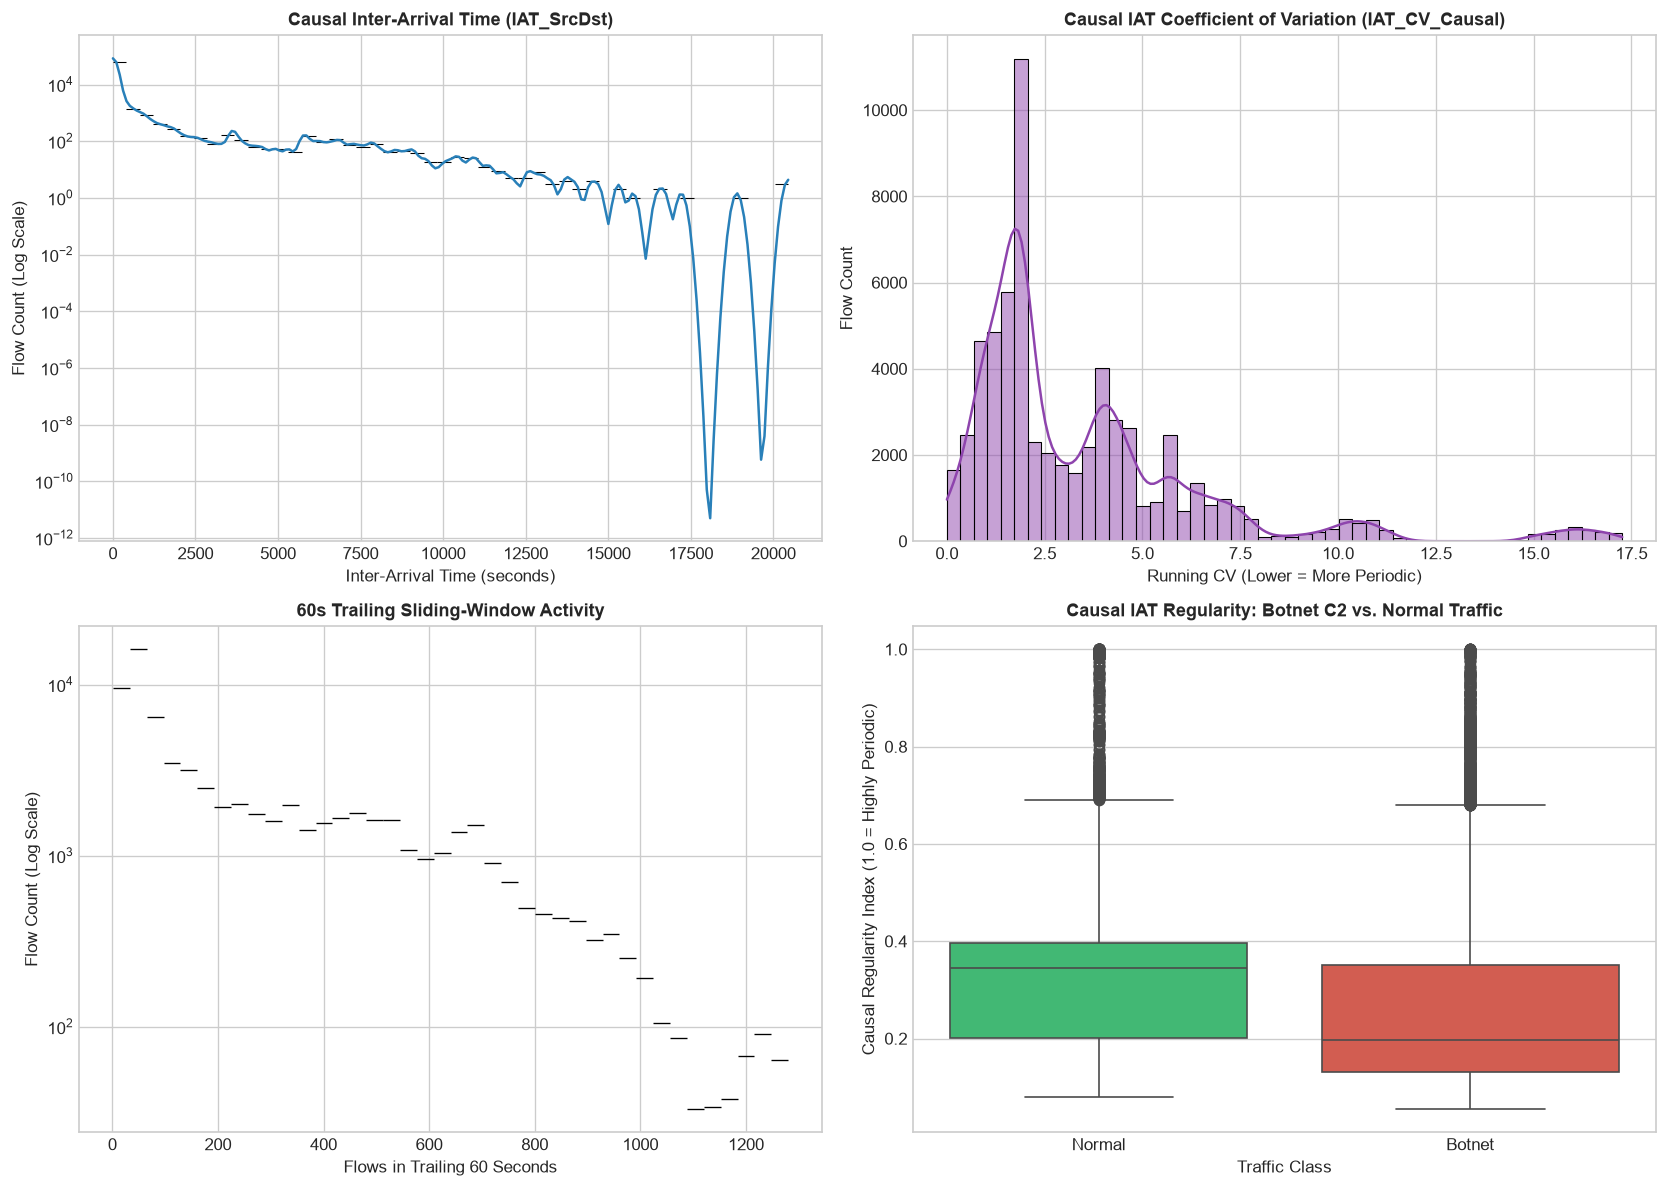

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Causal IAT Distribution
sns.histplot(df['IAT_SrcDst'].dropna(), bins=50, kde=True, ax=axes[0, 0], color='#2980b9', log_scale=(False, True))
axes[0, 0].set_title("Causal Inter-Arrival Time (IAT_SrcDst)", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Inter-Arrival Time (seconds)")
axes[0, 0].set_ylabel("Flow Count (Log Scale)")

# Plot 2: Causal IAT CV
sns.histplot(df['IAT_CV_Causal'].dropna(), bins=50, kde=True, ax=axes[0, 1], color='#8e44ad')
axes[0, 1].set_title("Causal IAT Coefficient of Variation (IAT_CV_Causal)", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Running CV (Lower = More Periodic)")
axes[0, 1].set_ylabel("Flow Count")

# Plot 3: 60s Sliding Window Density
sns.histplot(df['Src_Flows_60s'], bins=40, ax=axes[1, 0], color='#e67e22', log_scale=(False, True))
axes[1, 0].set_title("60s Trailing Sliding-Window Activity", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Flows in Trailing 60 Seconds")
axes[1, 0].set_ylabel("Flow Count (Log Scale)")

# Plot 4: Botnet vs Normal Causal Regularity Comparison
sns.boxplot(data=df, x='TrafficClass', y='IAT_Regularity_Causal', palette={'Botnet': '#e74c3c', 'Normal': '#2ecc71'}, ax=axes[1, 1])
axes[1, 1].set_title("Causal IAT Regularity: Botnet C2 vs. Normal Traffic", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Traffic Class")
axes[1, 1].set_ylabel("Causal Regularity Index (1.0 = Highly Periodic)")

plt.tight_layout()
plt.show()

### 12. Save Output Datasets & Reports
Export corrected online features dataset, online model dataset, audit report, and pipeline summary to `data/processed/CTU13/`.

In [12]:
out_online_full_path = processed_dir / 'ctu13_c2_online_features.csv'
out_online_model_path = processed_dir / 'ctu13_c2_online_model_features.csv'
out_audit_path = processed_dir / 'ctu13_online_feature_audit.csv'
out_summary_path = processed_dir / 'ctu13_online_feature_summary.csv'

# 1. Full online dataset (metadata + labels + all causal features)
df.to_csv(out_online_full_path, index=False)
full_online_size_mb = out_online_full_path.stat().st_size / (1024 * 1024)
print(f"1. Saved Full Online Dataset: {out_online_full_path.name} ({full_online_size_mb:.2f} MB)")

# 2. Online model features dataset (only numerical C2_ONLINE_FEATURE_COLUMNS + BinaryLabel)
c2_online_model_df.to_csv(out_online_model_path, index=False)
model_online_size_mb = out_online_model_path.stat().st_size / (1024 * 1024)
print(f"2. Saved Online Model Dataset: {out_online_model_path.name} ({model_online_size_mb:.2f} MB)")

# 3. Feature audit report
audit_df.to_csv(out_audit_path, index=False)
print(f"3. Saved Feature Audit Report: {out_audit_path.name}")

# 4. Pipeline summary
summary_data = [
    {"Metric": "total_rows", "Value": len(df)},
    {"Metric": "online_feature_count", "Value": len(C2_ONLINE_FEATURE_COLUMNS)},
    {"Metric": "offline_feature_count", "Value": 1},
    {"Metric": "training_rows", "Value": len(train_df)},
    {"Metric": "testing_rows", "Value": len(test_df)},
    {"Metric": "training_start", "Value": str(train_df['StartTime'].min())},
    {"Metric": "training_end", "Value": str(train_df['StartTime'].max())},
    {"Metric": "testing_start", "Value": str(test_df['StartTime'].min())},
    {"Metric": "testing_end", "Value": str(test_df['StartTime'].max())}
]
summary_df = pd.DataFrame(summary_data)
summary_df.to_csv(out_summary_path, index=False)
print(f"4. Saved Online Pipeline Summary: {out_summary_path.name}")
display(summary_df)

1. Saved Full Online Dataset: ctu13_c2_online_features.csv (32.70 MB)


2. Saved Online Model Dataset: ctu13_c2_online_model_features.csv (24.53 MB)
3. Saved Feature Audit Report: ctu13_online_feature_audit.csv
4. Saved Online Pipeline Summary: ctu13_online_feature_summary.csv


,Metric,Value
0,total_rows,71219
1,online_feature_count,46
2,offline_feature_count,1
3,training_rows,49853
4,testing_rows,21366
5,training_start,2011-08-10 09:46:53.160043+00:00
6,training_end,2011-08-10 13:52:15.347006+00:00
7,testing_start,2011-08-10 13:52:16.207398+00:00
8,testing_end,2011-08-10 15:54:07.198435+00:00


### 13. Final Quality and Integrity Validation
Verify that all assertions and output constraints are satisfied.

In [13]:
# Assertions
assert out_online_full_path.exists(), "Full online feature file does not exist."
assert out_online_model_path.exists(), "Model feature file does not exist."
assert out_audit_path.exists(), "Feature audit file does not exist."
assert out_summary_path.exists(), "Summary file does not exist."

assert 'BinaryLabel' not in C2_ONLINE_FEATURE_COLUMNS, "Data leakage: BinaryLabel in feature columns."
assert 'TrafficClass' not in C2_ONLINE_FEATURE_COLUMNS, "Data leakage: TrafficClass in feature columns."
assert 'Label' not in C2_ONLINE_FEATURE_COLUMNS, "Data leakage: Label in feature columns."
assert 'SrcAddr' not in C2_ONLINE_FEATURE_COLUMNS, "Identifier leakage: SrcAddr in feature columns."
assert 'DstAddr' not in C2_ONLINE_FEATURE_COLUMNS, "Identifier leakage: DstAddr in feature columns."
assert 'TimeUntilNext_SrcDst' not in C2_ONLINE_FEATURE_COLUMNS, "Temporal leakage: Future lookahead feature in online feature list."

assert c2_online_model_df[C2_ONLINE_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Null values remain in model features."
assert np.isinf(c2_online_model_df[C2_ONLINE_FEATURE_COLUMNS].values).sum() == 0, "Infinities remain in model features."
assert set(c2_online_model_df['BinaryLabel'].unique()) == {0, 1}, "Invalid BinaryLabel values."

print("==================================================")
print("STRICT ONLINE C2 FEATURE PIPELINE COMPLETE")
print("==================================================")
print(f"Final Row Count: {len(df):,}")
print(f"Number of Online-Safe Features: {len(C2_ONLINE_FEATURE_COLUMNS)}")
print(f"Number of Offline-Only Features: 1 (TimeUntilNext_SrcDst)")
print(f"Training Period Size: {len(train_df):,} rows (70%)")
print(f"Testing Period Size: {len(test_df):,} rows (30%)")
print(f"Output File 1: {out_online_full_path.name} ({full_online_size_mb:.2f} MB)")
print(f"Output File 2: {out_online_model_path.name} ({model_online_size_mb:.2f} MB)")
print(f"Output File 3: {out_audit_path.name}")
print(f"Output File 4: {out_summary_path.name}")
print("\n✅ All temporal causality, zero-leakage, and integrity checks passed.")

STRICT ONLINE C2 FEATURE PIPELINE COMPLETE
Final Row Count: 71,219
Number of Online-Safe Features: 46
Number of Offline-Only Features: 1 (TimeUntilNext_SrcDst)
Training Period Size: 49,853 rows (70%)
Testing Period Size: 21,366 rows (30%)
Output File 1: ctu13_c2_online_features.csv (32.70 MB)
Output File 2: ctu13_c2_online_model_features.csv (24.53 MB)
Output File 3: ctu13_online_feature_audit.csv
Output File 4: ctu13_online_feature_summary.csv

✅ All temporal causality, zero-leakage, and integrity checks passed.


### 14. Summary of Causal Correction Findings

1. **Strict Temporal Causality**: All 46 online-safe numerical features in `C2_ONLINE_FEATURE_COLUMNS` strictly evaluate only past and current flow observations ($t \le T$).
2. **Causal Running Statistics**: Global full-dataset averages were replaced with expanding historical window statistics (`IAT_RunningMean_SrcDst`, `IAT_RunningStd_SrcDst`, `IAT_RunningMin_SrcDst`, `IAT_RunningMax_SrcDst`, `IAT_CV_Causal`, `IAT_Regularity_Causal`).
3. **Cumulative Endpoint Tracking**: Connection counts and fan-out ratios (`Src_Flows_BeforeOrAtT`, `Src_UniqueDst_BeforeOrAtT`, `RepeatRatio_SrcDst_Causal`, `DstFanoutRatio_Causal`) represent dynamic connection accumulation up to time $T$.
4. **Historical Calibration Boundary**: Behavioral thresholds (95th quantile high-frequency source, median duration) and model feature median imputations were calibrated **strictly on the historical Training Period (first 70% of chronological flows)** and applied forward without test-set leakage.
5. **Real-Time Deployment Readiness**: The resulting dataset (`ctu13_c2_online_model_features.csv`) is strictly aligned with real-time stream processing requirements for subsequent DBSCAN, Isolation Forest, and supervised C2 detection engine training.